In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import median_filter
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec

In [2]:
raddir = '/glade/derecho/scratch/brendanc/fates_output/radiation/CLM_rad'
precipdir = '/glade/derecho/scratch/brendanc/fates_output/radiation/CLM_precip'
tempdir = '/glade/derecho/scratch/brendanc/fates_output/radiation/CLM_temperature'

In [3]:
case1 = xr.open_dataset(raddir + "/GRAIN4D.CLM5.1.dev171.G6-1.5K_case1_2050-2069.clm2.h1.NPP.nc")
case1 = case1["__xarray_dataarray_variable__"]
case2 = xr.open_dataset(raddir + "/GRAIN4D.CLM5.1.dev171.G6-1.5K_case2_2050-2069.clm2.h1.NPP.nc")
case2 = case2["__xarray_dataarray_variable__"] 
ssp = xr.open_dataset(raddir + "/GRAIN4D.CLM5.1.dev171.SSP245_006_2050-2069.clm2.h1.NPP.nc")
ssp = ssp["__xarray_dataarray_variable__"] 
precip = xr.open_dataset(precipdir + "/GRAIN4D.CLM5.1.dev171.G6-1.5K_precip_2050-2069.clm2.h1.NPP.nc")
precip = precip["__xarray_dataarray_variable__"] 
temp = xr.open_dataset(tempdir + "/GRAIN4D.CLM5.1.dev171.G6-1.5K_temperature_2050-2069_final.clm2.h1.NPP.nc")
temp = temp["__xarray_dataarray_variable__"] 

In [4]:
case1 = case1.sel(time=slice('2050-01-01', '2069-12-31')) * 31536000
case2 = case2.sel(time=slice('2050-01-01', '2069-12-31')) * 31536000
ssp = ssp.sel(time=slice('2050-01-01', '2069-12-31')) * 31536000
precip = precip.sel(time=slice('2050-01-01', '2069-12-31')) * 31536000
temp = temp.sel(time=slice('2050-01-01', '2069-12-31')) * 31536000

In [5]:
case1_annual = case1.resample(time='YE').mean(skipna=True)
case2_annual = case2.resample(time='YE').mean(skipna=True)
ssp_annual   = ssp.resample(time='YE').mean(skipna=True)
precip_annual   = precip.resample(time='YE').mean(skipna=True)
temp_annual   = temp.resample(time='YE').mean(skipna=True)

In [6]:
ssp_tavg   = ssp_annual.mean(dim='time')
case1_tavg = case1_annual.mean(dim='time')
case2_tavg = case2_annual.mean(dim='time')
temp_tavg = temp_annual.mean(dim='time')
precip_tavg = precip_annual.mean(dim='time')

In [7]:
filedir = '/glade/derecho/scratch/brendanc/hilla_yields'
landuse = xr.open_dataset(filedir + "/landuse.timeseries_0.9x1.25_SSP2-4.5_78pfts_CMIP6_simyr1850-2100_c190102.nc")

In [8]:
def median_smooth_da(da, size=3):
    arr = da.values.copy()
    nan_mask = np.isnan(arr)
    arr_filled = np.where(nan_mask, np.nanmedian(arr), arr)
    smoothed = median_filter(arr_filled, size=size)
    smoothed[nan_mask] = np.nan
    return da.copy(data=smoothed)

def compute_zonal_diffs(pft_list, size=3):
    case1_pft  = case1_tavg.sel(pft=pft_list).mean(dim='pft')
    case2_pft  = case2_tavg.sel(pft=pft_list).mean(dim='pft')
    ssp_pft    = ssp_tavg.sel(pft=pft_list).mean(dim='pft')
    temp_pft   = temp_tavg.sel(pft=pft_list).mean(dim='pft')
    precip_pft = precip_tavg.sel(pft=pft_list).mean(dim='pft')
    tot_rad_diff = median_smooth_da(case1_pft  - ssp_pft,   size=size)
    dirdif_diff  = median_smooth_da(case2_pft  - case1_pft, size=size)
    temp_diff    = median_smooth_da(temp_pft   - ssp_pft,   size=size)
    precip_diff  = median_smooth_da(precip_pft - ssp_pft,   size=size)
    def zonal(da):
        n_valid = da.count(dim='lon')
        return da.mean(dim='lon', skipna=True).where(n_valid >= 1)
    return [zonal(tot_rad_diff), zonal(dirdif_diff),
            zonal(temp_diff), zonal(precip_diff)]

if 'lat' in landuse.coords:
    pct_lat = landuse['lat'].values
elif 'LATIXY' in landuse:
    pct_lat = landuse['LATIXY'].isel(lsmlon=0).values
else:
    pct_lat = landuse['lsmlat'].values      

def compute_zonal_pct(pft_list, years=slice(2050, 2069)):
    return (landuse['PCT_NAT_PFT'].sel(natpft=pft_list).sum('natpft')
              .sel(time=years).mean('time').mean('lsmlon'))

bdt_pfts, nlet_pfts, c3_pfts, c4_pfts = [4, 5,6,7,8], [1,2,3], [13], [14]
pft_groups   = [bdt_pfts, nlet_pfts, c3_pfts, c4_pfts]
group_titles = ["CLM Broadleaf Trees", "CLM Needleleaf Trees",
                "CLM C3 Grass", "CLM C4 Grass"]
labels = ['Total radiation', 'Direct/diffuse radiation',
          'Temperature', 'Precipitation']
colors = ['tab:blue', 'tab:orange', 'tab:red', 'tab:green']

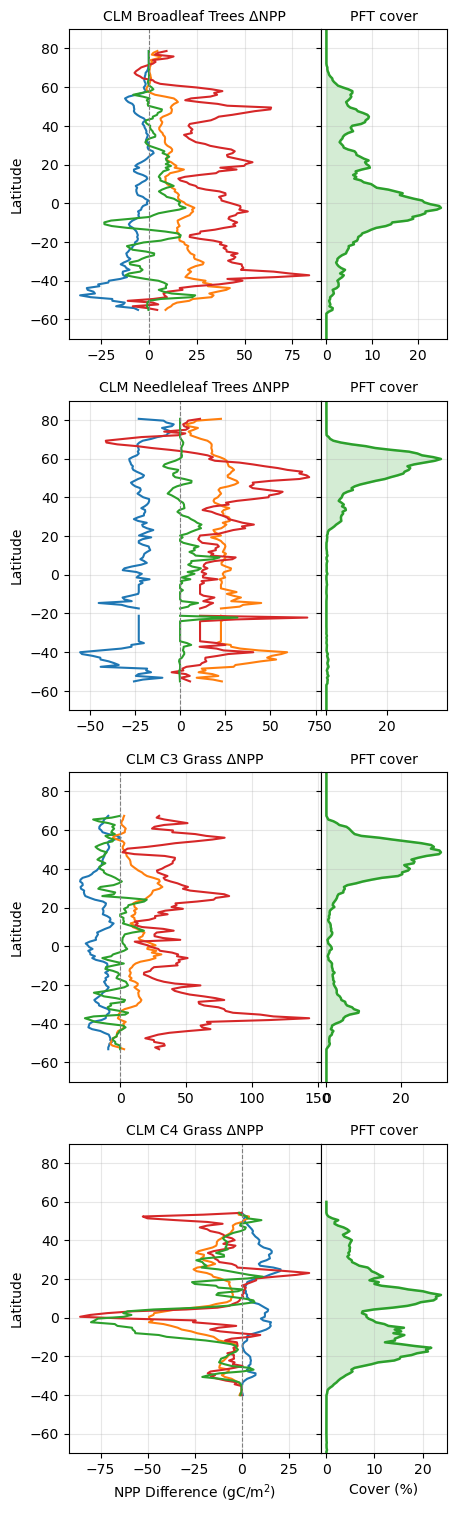

In [9]:
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec

fig = plt.figure(figsize=(4.5, 16))

outer = GridSpec(4, 1, figure=fig, hspace=0.2)

n_groups = len(pft_groups)
first_ax = None  
for g, (pft_list, group_title) in enumerate(zip(pft_groups, group_titles)):
    row, col = g, 0

    inner = GridSpecFromSubplotSpec(
        1, 2, subplot_spec=outer[row, col],
        width_ratios=[2, 1], wspace=0.0)

    if first_ax is None:
        npp_ax = fig.add_subplot(inner[0, 0]); first_ax = npp_ax
    else:
        npp_ax = fig.add_subplot(inner[0, 0], sharey=first_ax)
    pct_ax = fig.add_subplot(inner[0, 1], sharey=first_ax)

    npp_data = compute_zonal_diffs(pft_list, size=3)
    if pft_list == c4_pfts:                        # drop noisy C4 > 60N
        npp_data = [da.where(da['lat'] <= 60) for da in npp_data]
    for da, label, color in zip(npp_data, labels, colors):
        npp_ax.plot(da, da['lat'], label=label, color=color, lw=1.5)
    npp_ax.axvline(0, color="gray", lw=0.8, ls="--")
    npp_ax.set_title(f"{group_title} ΔNPP", fontsize=10)

    pct_prof = compute_zonal_pct(pft_list)
    lat_p, val_p = pct_lat, pct_prof.values
    if pft_list == c4_pfts:                        # match NPP masking
        val_p = np.where(lat_p <= 60, val_p, np.nan)
    pct_ax.plot(val_p, lat_p, color='tab:green', lw=1.8)
    pct_ax.fill_betweenx(lat_p, 0, val_p, alpha=0.2, color='tab:green')
    pct_ax.set_title("PFT cover", fontsize=10)

    for ax in (npp_ax, pct_ax):
        ax.set_ylim(-70, 90)
        ax.grid(alpha=0.3)

    plt.setp(pct_ax.get_yticklabels(), visible=False)

    npp_ax.set_ylabel("Latitude")

    if row == n_groups - 1:
        npp_ax.set_xlabel("NPP Difference (gC/m$^2$)")
        pct_ax.set_xlabel("Cover (%)")
#    if g == n_groups - 1:
#        npp_ax.legend(fontsize=8, loc='lower left')

#fig.suptitle("CLM Zonal-mean ΔNPP and PFT cover (2050–2069)", fontsize=10)
fig.subplots_adjust(left=0.12, right=0.96, top=0.94, bottom=0.05)
plt.show()

#savedir = "/glade/derecho/scratch/brendanc/fates_output/radiation"
#plt.savefig(f"{savedir}/CLM_NPP_PCT_lat_lines.png", dpi=600, bbox_inches="tight")